# Práctica 2. Análisis Exploratorio de Datos (EDA) y preparación de datasets

**Alumno:** Diego Raymundo Hernández Alonso
**Datasets:** Titanic y Adult Income

**Objetivo:** diagnosticar la calidad de dos datasets de clasificación binaria, justificar las decisiones de preprocesamiento y medir su efecto en un clasificador.

**Contenido:**

1. Paso 2. Comprensión del dominio y data profiling
2. Paso 3. Análisis exploratorio (EDA)
3. Paso 4. Imputación de valores perdidos
4. Paso 5. Outliers (winsorización)
5. Paso 6. Tratamiento de desbalance
6. Conclusiones y recomendación

Para medir el efecto de cada decisión se usa siempre el mismo modelo: una regresión logística con datos escalados, entrenada con el 70% de los datos y evaluada con el 30% restante (separación estratificada, `random_state=42`).

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from imblearn.pipeline import make_pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

sns.set_theme(style="whitegrid")

ruta = "."
carpeta_graf = f"{ruta}/graficas"
os.makedirs(carpeta_graf, exist_ok=True)

titanic = pd.read_csv(f"{ruta}/datos/titanic.csv")
adult = pd.read_csv(f"{ruta}/datos/adult.csv", na_values="?")

print("Titanic:", titanic.shape)
print("Adult:", adult.shape)

Titanic: (891, 12)
Adult: (32561, 15)


In [2]:
def perfil(df):
    tabla = pd.DataFrame({
        "tipo": df.dtypes,
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(2),
        "unicos": df.nunique(),
    })
    numericas = df.select_dtypes("number")
    stats = numericas.agg(["min", "max", "mean", "median", "std", "skew"]).T
    percentiles = numericas.quantile([0.01, 0.25, 0.75, 0.99]).T
    percentiles.columns = ["p1", "p25", "p75", "p99"]
    return tabla.join(stats).join(percentiles).round(2)

def valor_dominante(df):
    return df.apply(lambda col: col.value_counts(normalize=True, dropna=False).iloc[0]).sort_values(ascending=False).round(3)

def revisar_texto(df):
    for col in df.select_dtypes(exclude="number").columns:
        valores = df[col].dropna().astype(str)
        espacios = (valores != valores.str.strip()).sum()
        repetidas = valores.nunique() - valores.str.strip().str.lower().nunique()
        print(f"{col}: {espacios} con espacios de más, {repetidas} repetidas por mayúsculas")

def atipicos_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    rango = q3 - q1
    bajo, alto = q1 - 1.5 * rango, q3 + 1.5 * rango
    print(f"{serie.name}: {((serie < bajo) | (serie > alto)).sum()} atípicos, límites {bajo:.2f} a {alto:.2f}")

def evaluar(X, y, tecnica=None):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    modelo = make_pipeline(StandardScaler(), tecnica, LogisticRegression(max_iter=1000))
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    return {
        "accuracy": accuracy_score(y_test, pred),
        "precision_minoritaria": precision_score(y_test, pred),
        "recall_minoritaria": recall_score(y_test, pred),
        "f1_minoritaria": f1_score(y_test, pred),
    }

## Paso 2. Comprensión del dominio y Data Profiling

### 2.1 Titanic

**Dominio:** registros de los pasajeros del RMS Titanic, que se hundió en abril de 1912. Se usa el conjunto de entrenamiento de Kaggle (891 pasajeros). La pregunta es qué características hicieron más probable sobrevivir.

| Variable | Descripción | Tipo | Valores válidos |
|---|---|---|---|
| PassengerId | Número de pasajero | Entero | 1 a 891, único |
| Survived | Sobrevivió (objetivo) | Binaria | 0 = no, 1 = sí |
| Pclass | Clase del boleto | Categórica ordinal | 1, 2, 3 |
| Name | Nombre del pasajero | Texto | Libre |
| Sex | Sexo | Categórica | male, female |
| Age | Edad en años | Numérica | 0 a ~100 (menores de 1 año vienen con decimales) |
| SibSp | Hermanos o cónyuges a bordo | Entero | 0 o más |
| Parch | Padres o hijos a bordo | Entero | 0 o más |
| Ticket | Número de boleto | Texto | Libre |
| Fare | Precio del boleto (libras) | Numérica | 0 o más |
| Cabin | Número de cabina | Texto | Libre |
| Embarked | Puerto de embarque | Categórica | C = Cherbourg, Q = Queenstown, S = Southampton |

**Preguntas del dominio:**

- **Fuente y licencia:** competencia *Titanic - Machine Learning from Disaster* de Kaggle. Los datos vienen de listas históricas de pasajeros (Encyclopedia Titanica). Kaggle no les asigna una licencia abierta tipo Creative Commons; su uso se rige por las reglas de la competencia. Aquí se usan solo con fines académicos.
- **¿Qué representa cada fila?** Un pasajero. El archivo tiene 891 filas y 12 columnas.
- **¿La variable objetivo estaría disponible en un escenario real?** Solo después del naufragio. Por eso este dataset sirve para entender qué factores influyeron en la supervivencia, no para predecir en tiempo real.
- **¿Hay identificadores o fugas de información?** `PassengerId` y `Name` identifican a cada pasajero y `Ticket` es casi único. Ninguna variable se registró después del hundimiento.
- **¿Qué decisiones podrían afectar de forma desigual a distintos grupos?** El sexo y la clase cambian mucho la supervivencia. Además, la edad falta más en tercera clase, así que imputarla afecta más a ese grupo. Son datos de personas reales con nombre, así que `Name` se elimina.

In [3]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
perfil(titanic)

,tipo,nulos,%_nulos,unicos,min,max,mean,median,std,skew,p1,p25,p75,p99
PassengerId,int64,0,0.00,891,1.00,891.00,446.00,446.00,257.35,0.00,9.9,223.50,668.5,882.10
Survived,int64,0,0.00,2,0.00,1.00,0.38,0.00,0.49,0.48,0.0,0.00,1.0,1.00
Pclass,int64,0,0.00,3,1.00,3.00,2.31,3.00,0.84,-0.63,1.0,2.00,3.0,3.00
Name,str,0,0.00,891,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,str,0,0.00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,float64,177,19.87,88,0.42,80.00,29.70,28.00,14.53,0.39,1.0,20.12,38.0,65.87
SibSp,int64,0,0.00,7,0.00,8.00,0.52,0.00,1.10,3.70,0.0,0.00,1.0,5.00
Parch,int64,0,0.00,7,0.00,6.00,0.38,0.00,0.81,2.75,0.0,0.00,0.0,4.00
Ticket,str,0,0.00,681,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,float64,0,0.00,248,0.00,512.33,32.20,14.45,49.69,4.79,0.0,7.91,31.0,249.01


In [5]:
for col in ["Pclass", "Sex", "Embarked", "SibSp", "Parch"]:
    print(titanic[col].value_counts(dropna=False), "\n")

Pclass
3    491
1    216
2    184
Name: count, dtype: int64 

Sex
male      577
female    314
Name: count, dtype: int64 

Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64 

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64 

Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64 



In [6]:
print(titanic["Survived"].value_counts())
print(titanic["Survived"].value_counts(normalize=True).round(3))

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


In [7]:
posibles_id = [c for c in titanic.columns if titanic[c].nunique() == len(titanic)]
print("Columnas con un valor distinto por fila:", posibles_id)
print("Filas duplicadas:", titanic.duplicated().sum())
print("Boletos con precio 0:", (titanic["Fare"] == 0).sum())
print("Edades estimadas (terminan en .5):", ((titanic["Age"] % 1 == 0.5) & (titanic["Age"] >= 1)).sum())

Columnas con un valor distinto por fila: ['PassengerId', 'Name']
Filas duplicadas: 0
Boletos con precio 0: 15
Edades estimadas (terminan en .5): 18


In [8]:
print(valor_dominante(titanic).head(5), "\n")
revisar_texto(titanic)

Cabin       0.771
Parch       0.761
Embarked    0.723
SibSp       0.682
Sex         0.648
dtype: float64 

Name: 2 con espacios de más, 0 repetidas por mayúsculas
Sex: 0 con espacios de más, 0 repetidas por mayúsculas
Ticket: 0 con espacios de más, 0 repetidas por mayúsculas
Cabin: 0 con espacios de más, 0 repetidas por mayúsculas
Embarked: 0 con espacios de más, 0 repetidas por mayúsculas


In [9]:
titanic["Age"].isna().groupby(titanic["Pclass"]).mean().round(3)

Pclass
1    0.139
2    0.060
3    0.277
Name: Age, dtype: float64

In [10]:
print(titanic.groupby("Sex")["Survived"].mean().round(3))
print(titanic.groupby("Pclass")["Survived"].mean().round(3))

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64


**Hallazgos del profiling (Titanic):**

- **Variable objetivo:** `Survived`. 549 no sobrevivieron (61.6%) y 342 sí (38.4%).
- **Identificadores:** `PassengerId` y `Name` tienen un valor distinto por fila, así que no aportan para predecir. `Ticket` también es casi único (681 valores en 891 filas).
- **Nulos:** `Cabin` tiene 77.1% de nulos, demasiados para imputar con confianza. `Age` tiene 19.9% y `Embarked` solo 2 registros. No hay filas duplicadas.
- **Asimetría y percentiles:** `Fare` (4.79), `SibSp` (3.70) y `Parch` (2.75) están muy sesgadas a la derecha. El 99% de los boletos cuesta 249.01 o menos, pero el máximo es 512.33. `Age` es casi simétrica (0.39).
- **Rangos:** `Age` va de 0.42 a 80 años (media 29.7). `Fare` va de 0 a 512.33, con media 32.2 y mediana 14.45. Esa diferencia indica una distribución muy cargada a la derecha, con posibles outliers. Hay 15 boletos con precio 0 que pueden ser tripulación o pases de cortesía.
- **Columnas casi constantes:** ninguna. El valor más dominante es el nulo de `Cabin` (77.1%), seguido de `Parch` = 0 (76.1%).
- **Categorías inconsistentes:** no hay. Solo 2 nombres tienen espacios de más, y `Name` se descarta.
- **Edades estimadas:** 18 pasajeros mayores de un año tienen una edad terminada en .5. En la documentación de Kaggle así se marcan las edades estimadas, así que no son errores, pero tampoco son exactas.
- **Nulos no aleatorios:** a la tercera clase le falta la edad en 27.7% de los casos, contra 13.9% en primera y 6% en segunda. Hay que tomarlo en cuenta al imputar.
- **Fugas de información:** no se ven variables que se hayan registrado después del hundimiento, así que no hay una fuga evidente.
- **Sesgos:** hay más hombres (577) que mujeres (314) y más de la mitad viajaba en tercera clase (491). La supervivencia cambia mucho por sexo (74.2% en mujeres contra 18.9% en hombres) y por clase (63% en primera contra 24.2% en tercera). Esto refleja la política de "mujeres y niños primero" y la ubicación de las cabinas.

### 2.2 Adult Income

**Dominio:** datos del censo de Estados Unidos de 1994, publicados en el repositorio UCI. Se usa el conjunto de entrenamiento (32,561 personas). El objetivo es predecir si una persona gana más de 50 mil dólares al año.

| Variable | Descripción | Tipo | Valores válidos |
|---|---|---|---|
| age | Edad | Numérica | 17 a 90 |
| workclass | Tipo de empleador | Categórica | Private, Self-emp, Gov, etc. |
| fnlwgt | Peso de muestreo del censo | Numérica | Positivo |
| education | Nivel de estudios | Categórica | 16 niveles |
| education-num | Nivel de estudios en número | Entero | 1 a 16 |
| marital-status | Estado civil | Categórica | 7 valores |
| occupation | Ocupación | Categórica | 14 valores |
| relationship | Rol en el hogar | Categórica | Husband, Wife, Own-child, etc. |
| race | Raza | Categórica | 5 valores |
| sex | Sexo | Categórica | Male, Female |
| capital-gain | Ganancias de capital | Numérica | 0 o más |
| capital-loss | Pérdidas de capital | Numérica | 0 o más |
| hours-per-week | Horas trabajadas por semana | Numérica | 1 a 99 |
| native-country | País de origen | Categórica | 41 países |
| income | Ingreso anual (objetivo) | Binaria | <=50K, >50K |

En el archivo original los valores faltantes vienen marcados como `?`.

**Preguntas del dominio:**

- **Fuente y licencia:** UCI Machine Learning Repository, *Adult* (Becker y Kohavi, 1996, DOI 10.24432/C5XW20), con licencia Creative Commons Attribution 4.0 (CC BY 4.0). Se puede usar y modificar dando crédito a la fuente.
- **¿Qué representa cada fila?** Una persona mayor de 16 años registrada en el censo de 1994. El archivo tiene 32,561 filas y 15 columnas.
- **¿La variable objetivo estaría disponible en un escenario real?** Sí, el ingreso se puede preguntar o comprobar. El problema es que los datos son de 1994 y el umbral de 50K no está ajustado por inflación, así que un modelo entrenado con ellos no aplicaría igual hoy.
- **¿Hay identificadores o fugas de información?** No hay identificadores. `fnlwgt` es un peso de muestreo del censo. Ninguna variable se calcula a partir del ingreso.
- **¿Qué decisiones podrían afectar de forma desigual a distintos grupos?** `sex`, `race` y `native-country` son atributos sensibles. Si un modelo así se usara para dar créditos o empleos, podría repetir la desigualdad que ya está en los datos. Quitar esas columnas no basta, porque `relationship` (Husband / Wife) revela el sexo de forma indirecta.

In [11]:
adult.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [12]:
perfil(adult)

,tipo,nulos,%_nulos,unicos,min,max,mean,median,std,skew,p1,p25,p75,p99
age,int64,0,0.00,73,17.0,90.0,38.58,37.0,13.64,0.56,17.0,28.0,48.0,74.0
workclass,str,1836,5.64,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,int64,0,0.00,21648,12285.0,1484705.0,189778.37,178356.0,105549.98,1.45,27185.8,117827.0,237051.0,510072.0
education,str,0,0.00,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,int64,0,0.00,16,1.0,16.0,10.08,10.0,2.57,-0.31,3.0,9.0,12.0,16.0
marital-status,str,0,0.00,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,str,1843,5.66,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,str,0,0.00,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,str,0,0.00,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,str,0,0.00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
for col in adult.select_dtypes(exclude="number").columns:
    print(adult[col].value_counts(normalize=True, dropna=False).mul(100).round(2).head(8), "\n")

workclass
Private             69.70
Self-emp-not-inc     7.80
Local-gov            6.43
NaN                  5.64
State-gov            3.99
Self-emp-inc         3.43
Federal-gov          2.95
Without-pay          0.04
Name: proportion, dtype: float64 

education
HS-grad         32.25
Some-college    22.39
Bachelors       16.45
Masters          5.29
Assoc-voc        4.24
11th             3.61
Assoc-acdm       3.28
10th             2.87
Name: proportion, dtype: float64 

marital-status
Married-civ-spouse       45.99
Never-married            32.81
Divorced                 13.65
Separated                 3.15
Widowed                   3.05
Married-spouse-absent     1.28
Married-AF-spouse         0.07
Name: proportion, dtype: float64 

occupation
Prof-specialty       12.71
Craft-repair         12.59
Exec-managerial      12.49
Adm-clerical         11.58
Sales                11.21
Other-service        10.12
Machine-op-inspct     6.15
NaN                   5.66
Name: proportion, dtype: float64

In [14]:
print(adult["income"].value_counts())
print(adult["income"].value_counts(normalize=True).round(3))

income
<=50K    24720
>50K      7841
Name: count, dtype: int64
income
<=50K    0.759
>50K     0.241
Name: proportion, dtype: float64


In [15]:
posibles_id = [c for c in adult.columns if adult[c].nunique() == len(adult)]
print("Columnas con un valor distinto por fila:", posibles_id)
print("Filas duplicadas:", adult.duplicated().sum())
print("Niveles de education con más de un education-num:", (adult.groupby("education")["education-num"].nunique() > 1).sum())
print("Filas sin workclass ni occupation:", (adult["workclass"].isna() & adult["occupation"].isna()).sum())

Columnas con un valor distinto por fila: []


Filas duplicadas: 24
Niveles de education con más de un education-num: 0
Filas sin workclass ni occupation: 1836


In [16]:
print("capital-gain en 0:", (adult["capital-gain"] == 0).mean().round(3))
print("capital-loss en 0:", (adult["capital-loss"] == 0).mean().round(3))
print("capital-gain = 99999:", (adult["capital-gain"] == 99999).sum())
print("hours-per-week = 99:", (adult["hours-per-week"] == 99).sum())
print("hours-per-week = 40:", (adult["hours-per-week"] == 40).mean().round(3))

capital-gain en 0: 0.917
capital-loss en 0: 0.953
capital-gain = 99999: 159
hours-per-week = 99: 85
hours-per-week = 40: 0.467


In [17]:
print(valor_dominante(adult).head(6), "\n")
revisar_texto(adult)
print("\nCategorías con menos casos:")
print(adult["workclass"].value_counts().tail(2))
print(adult["occupation"].value_counts().tail(1))
print(adult["native-country"].value_counts().tail(3))

capital-loss      0.953
capital-gain      0.917
native-country    0.896
race              0.854
income            0.759
workclass         0.697
dtype: float64 

workclass: 0 con espacios de más, 0 repetidas por mayúsculas
education: 0 con espacios de más, 0 repetidas por mayúsculas
marital-status: 0 con espacios de más, 0 repetidas por mayúsculas


occupation: 0 con espacios de más, 0 repetidas por mayúsculas


relationship: 0 con espacios de más, 0 repetidas por mayúsculas


race: 0 con espacios de más, 0 repetidas por mayúsculas


sex: 0 con espacios de más, 0 repetidas por mayúsculas


native-country: 0 con espacios de más, 0 repetidas por mayúsculas
income: 0 con espacios de más, 0 repetidas por mayúsculas

Categorías con menos casos:
workclass
Without-pay     14
Never-worked     7
Name: count, dtype: int64
occupation
Armed-Forces    9
Name: count, dtype: int64
native-country
Hungary               13
Scotland              12
Holand-Netherlands     1
Name: count, dtype: int64


In [18]:
gana_mas = adult["income"] == ">50K"
print(gana_mas.groupby(adult["sex"]).mean().round(3))
print(gana_mas.groupby(adult["race"]).mean().round(3))

sex
Female    0.109
Male      0.306
Name: income, dtype: float64
race
Amer-Indian-Eskimo    0.116
Asian-Pac-Islander    0.266
Black                 0.124
Other                 0.092
White                 0.256
Name: income, dtype: float64


**Hallazgos del profiling (Adult Income):**

- **Variable objetivo:** `income`. 24,720 personas ganan `<=50K` (75.9%) y 7,841 ganan `>50K` (24.1%).
- **Identificadores:** no hay ninguna columna que funcione como ID. `fnlwgt` no describe a la persona, es un peso que el censo usa para extrapolar a la población, así que se puede descartar.
- **Nulos:** solo en categóricas. `occupation` tiene 1,843 (5.7%), `workclass` 1,836 (5.6%) y `native-country` 583 (1.8%). Los nulos de `workclass` y `occupation` coinciden casi siempre. Hay 1,836 filas sin ninguno de los dos, y los otros 7 casos son personas `Never-worked`, que lógicamente no tienen ocupación.
- **Duplicados:** 24 filas repetidas. Al ser datos de censo, pueden ser personas distintas con el mismo perfil.
- **Redundancia:** `education` y `education-num` contienen la misma información (cada nivel tiene un único número), así que basta con una.
- **Asimetría:** `capital-gain` (11.95) y `capital-loss` (4.59) son las más sesgadas. `age` está un poco cargada a la derecha (0.56). `hours-per-week` es casi simétrica (0.23), pero el 46.7% de las filas vale exactamente 40.
- **Columnas casi constantes:** `capital-loss` vale 0 en el 95.3% de las filas y `capital-gain` en el 91.7%. `native-country` también está muy concentrada (89.6% United-States). No se eliminan, porque los pocos valores distintos sí dicen algo del ingreso.
- **Categorías inconsistentes:** en el archivo original de UCI todos los valores de texto empiezan con un espacio, que se quitó al preparar `adult.csv`. Después de eso no quedan espacios de más ni categorías repetidas por mayúsculas. Sí hay categorías con muy pocos casos: `Never-worked` (7), `Armed-Forces` (9), `Without-pay` (14) y `Holand-Netherlands` (1 persona).
- **Rangos y valores raros:** `age` va de 17 a 90 y `hours-per-week` de 1 a 99 (85 personas con exactamente 99, otro posible tope). En `capital-gain` el máximo es 99999 (159 personas), que parece un valor tope más que un dato real.
- **Fugas de información:** no hay variables calculadas a partir del ingreso. `relationship` repite información de `sex` y `marital-status` (Husband casi siempre es Male y Wife es Female), pero eso es redundancia, no fuga.
- **Sesgos:** 66.9% de los registros son hombres y 85.4% son de raza blanca. Además, el 30.6% de los hombres gana más de 50K contra solo el 10.9% de las mujeres. Por raza pasa algo parecido: 25.6% de las personas blancas gana más de 50K contra 12.4% de las personas negras. Un modelo entrenado así podría reproducir esa desigualdad, así que es un punto a cuidar.

## Paso 3. Análisis Exploratorio de Datos (EDA)

Por cada dataset se hacen las mismas gráficas. Cada una responde una pregunta:

| Gráfica | Pregunta |
|---|---|
| Distribuciones numéricas | ¿Cómo se reparten los valores y qué tan sesgados están? |
| Boxplots | ¿Hay valores atípicos y dónde están? |
| Categóricas | ¿Qué categorías dominan? |
| Distribución de clases | ¿Qué tan desbalanceada está la variable objetivo? |
| Matriz de correlación | ¿Qué variables numéricas se relacionan con el objetivo y entre sí? |
| Atributo vs objetivo | ¿Qué grupos tienen una tasa más alta de la clase positiva? |
| Objetivo por rangos de edad | ¿Hay relaciones que la correlación no alcanza a ver? |

### 3.1 Titanic

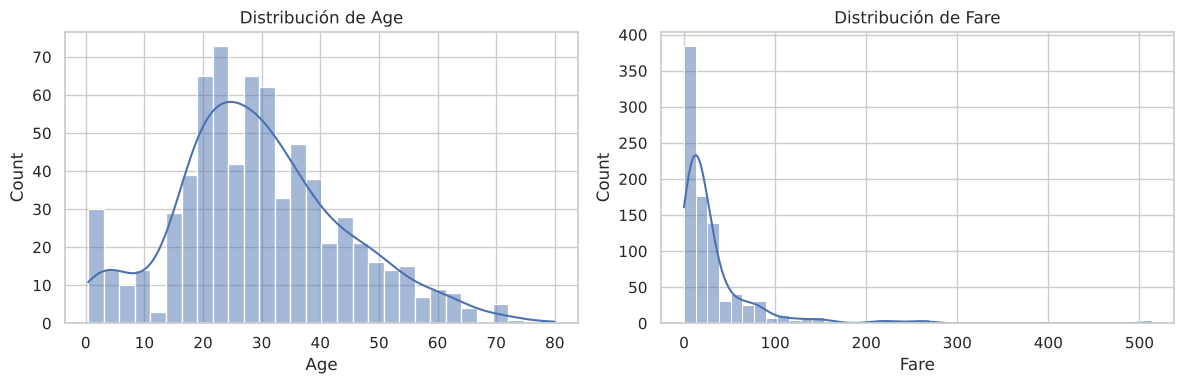

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(titanic["Age"], bins=30, kde=True, ax=ax[0])
ax[0].set_title("Distribución de Age")
sns.histplot(titanic["Fare"], bins=40, kde=True, ax=ax[1])
ax[1].set_title("Distribución de Fare")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/titanic_distribuciones.png")
plt.show()

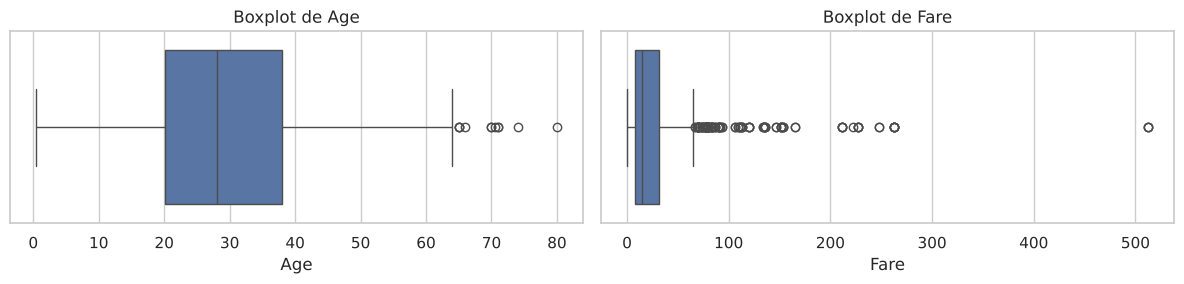

Age: 11 atípicos, límites -6.69 a 64.81
Fare: 116 atípicos, límites -26.72 a 65.63


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
sns.boxplot(x=titanic["Age"], ax=ax[0])
ax[0].set_title("Boxplot de Age")
sns.boxplot(x=titanic["Fare"], ax=ax[1])
ax[1].set_title("Boxplot de Fare")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/titanic_boxplots.png")
plt.show()

atipicos_iqr(titanic["Age"])
atipicos_iqr(titanic["Fare"])

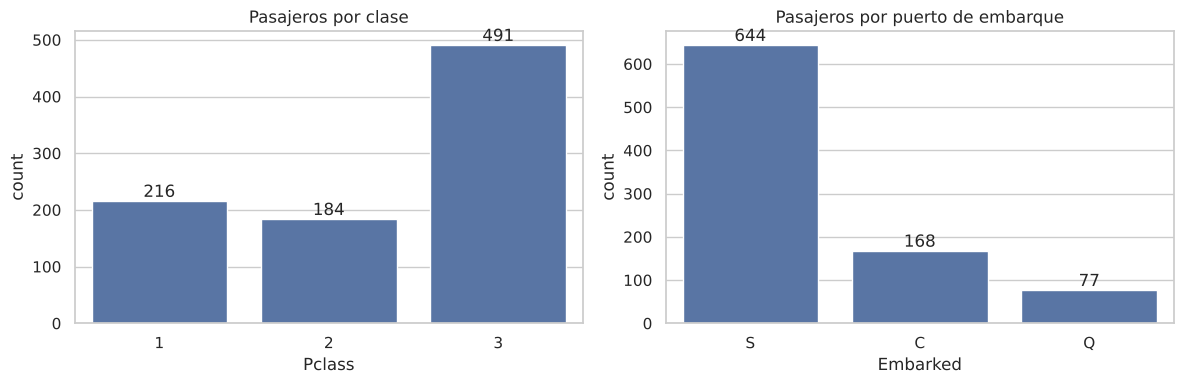

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="Pclass", data=titanic, ax=ax[0])
ax[0].set_title("Pasajeros por clase")
ax[0].bar_label(ax[0].containers[0])
sns.countplot(x="Embarked", data=titanic, ax=ax[1])
ax[1].set_title("Pasajeros por puerto de embarque")
ax[1].bar_label(ax[1].containers[0])
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/titanic_categoricas.png")
plt.show()

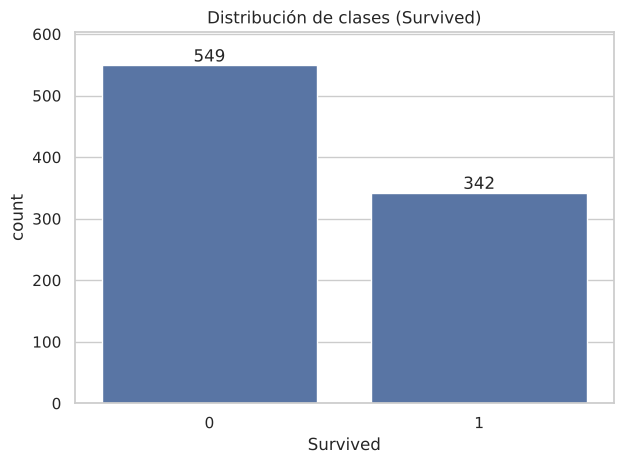

In [22]:
ax = sns.countplot(x="Survived", data=titanic)
ax.bar_label(ax.containers[0])
ax.margins(y=0.1)
plt.title("Distribución de clases (Survived)")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/titanic_clases.png")
plt.show()

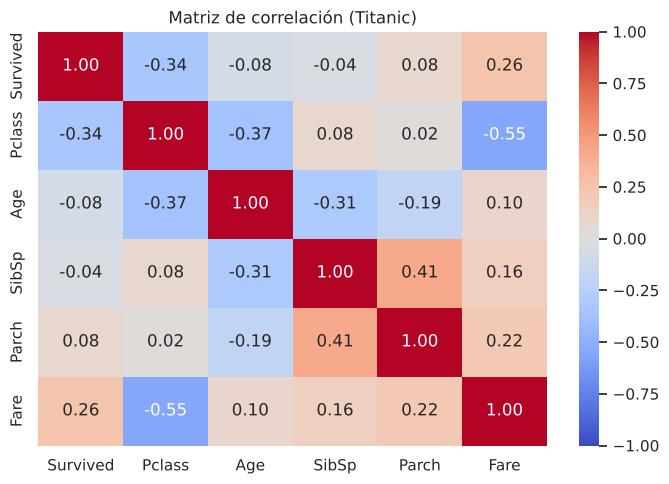

In [23]:
corr_tit = titanic.drop(columns="PassengerId").select_dtypes("number").corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr_tit, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación (Titanic)")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/titanic_correlacion.png")
plt.show()

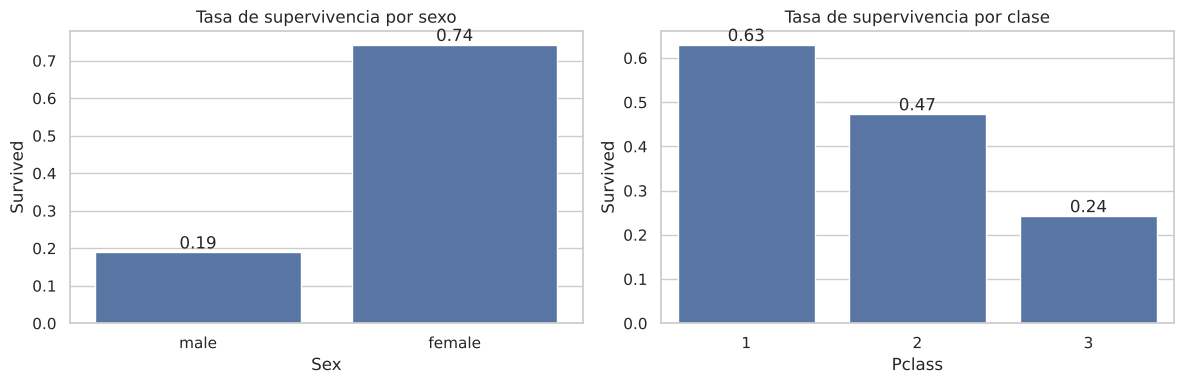

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x="Sex", y="Survived", data=titanic, errorbar=None, ax=ax[0])
ax[0].set_title("Tasa de supervivencia por sexo")
ax[0].bar_label(ax[0].containers[0], fmt="%.2f")
sns.barplot(x="Pclass", y="Survived", data=titanic, errorbar=None, ax=ax[1])
ax[1].set_title("Tasa de supervivencia por clase")
ax[1].bar_label(ax[1].containers[0], fmt="%.2f")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/titanic_atributo_objetivo.png")
plt.show()

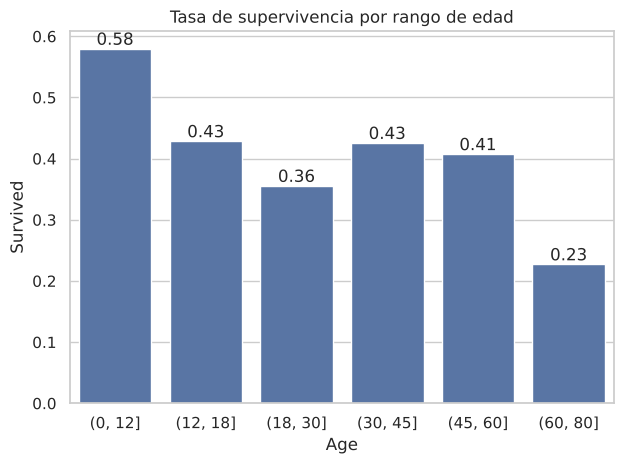

Pasajeros por rango: [69, 70, 270, 202, 81, 22]
Correlación de Age con Survived: -0.077


In [25]:
rangos_edad = pd.cut(titanic["Age"], bins=[0, 12, 18, 30, 45, 60, 80])
ax = sns.barplot(x=rangos_edad, y=titanic["Survived"], errorbar=None)
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Tasa de supervivencia por rango de edad")
plt.xlabel("Age")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/titanic_no_lineal.png")
plt.show()

print("Pasajeros por rango:", rangos_edad.value_counts(sort=False).tolist())
print("Correlación de Age con Survived:", round(titanic["Age"].corr(titanic["Survived"]), 3))

**Hallazgos del EDA (Titanic):**

- **Age:** la mayoría de los pasajeros tiene entre 20 y 40 años y hay un grupo pequeño de niños menores de 5. La distribución está poco sesgada (asimetría de 0.39) y la media (29.7) queda cerca de la mediana (28). En el boxplot solo aparecen 11 valores atípicos, arriba de 64.8 años, que son edades reales.
- **Fare:** está muy sesgada a la derecha (asimetría de 4.79). Tres de cada cuatro pasajeros pagaron 31 libras o menos, pero hay boletos de hasta 512. El boxplot marca 116 valores atípicos. Son tarifas reales de primera clase, no errores, así que conviene acotarlos (winsorizar) en lugar de borrarlos.
- **Categóricas:** más de la mitad viajaba en tercera clase (491 de 891) y el 72% embarcó en Southampton.
- **Clases:** 549 no sobrevivieron y 342 sí. El desbalance es moderado.
- **Correlación:** lo que más se relaciona con `Survived` es `Pclass` (-0.34) y `Fare` (0.26). `Pclass` y `Fare` están relacionadas entre sí (-0.55), porque primera clase costaba más. También se ve que `Age` baja conforme sube el número de clase (-0.37): en primera viajaba gente más grande. `Sex` no aparece porque es categórica, pero es el factor más fuerte.
- **Atributo vs objetivo:** sobrevivió el 74% de las mujeres contra el 19% de los hombres, y el 63% de primera clase contra el 24% de tercera.
- **Relación no lineal:** la correlación entre `Age` y `Survived` es casi cero (-0.08), pero eso no quiere decir que la edad no importe. Por rangos, los niños de 12 años o menos sobreviven 58%, entre 19 y 30 años baja a 36%, entre 31 y 60 sube a 41-43% y en mayores de 60 cae a 23% (aunque son solo 22 personas). Como la relación sube y baja, la correlación no la detecta.

### 3.2 Adult Income

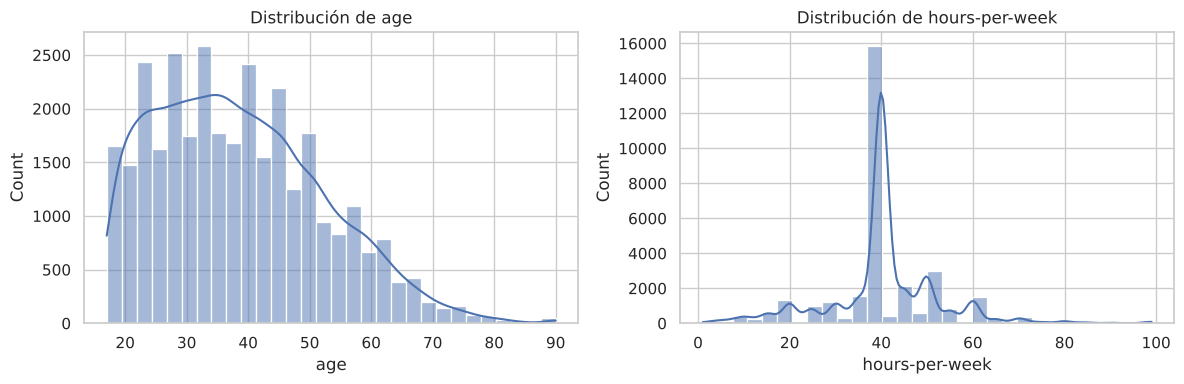

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(adult["age"], bins=30, kde=True, ax=ax[0])
ax[0].set_title("Distribución de age")
sns.histplot(adult["hours-per-week"], bins=30, kde=True, ax=ax[1])
ax[1].set_title("Distribución de hours-per-week")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/adult_distribuciones.png")
plt.show()

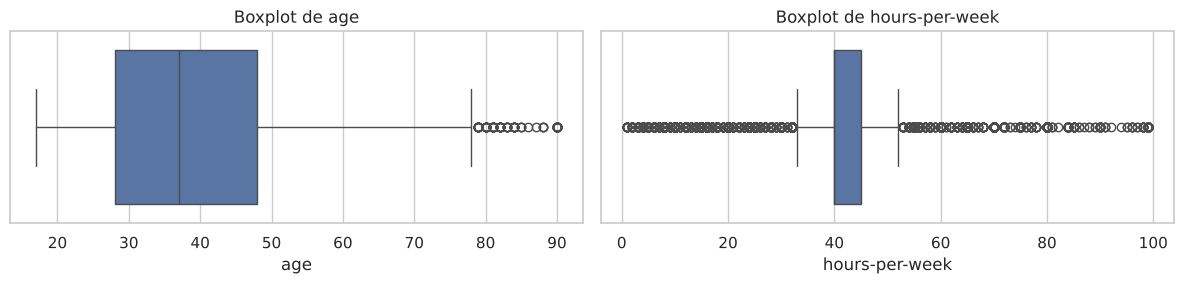

age: 143 atípicos, límites -2.00 a 78.00
hours-per-week: 9008 atípicos, límites 32.50 a 52.50


In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
sns.boxplot(x=adult["age"], ax=ax[0])
ax[0].set_title("Boxplot de age")
sns.boxplot(x=adult["hours-per-week"], ax=ax[1])
ax[1].set_title("Boxplot de hours-per-week")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/adult_boxplots.png")
plt.show()

atipicos_iqr(adult["age"])
atipicos_iqr(adult["hours-per-week"])

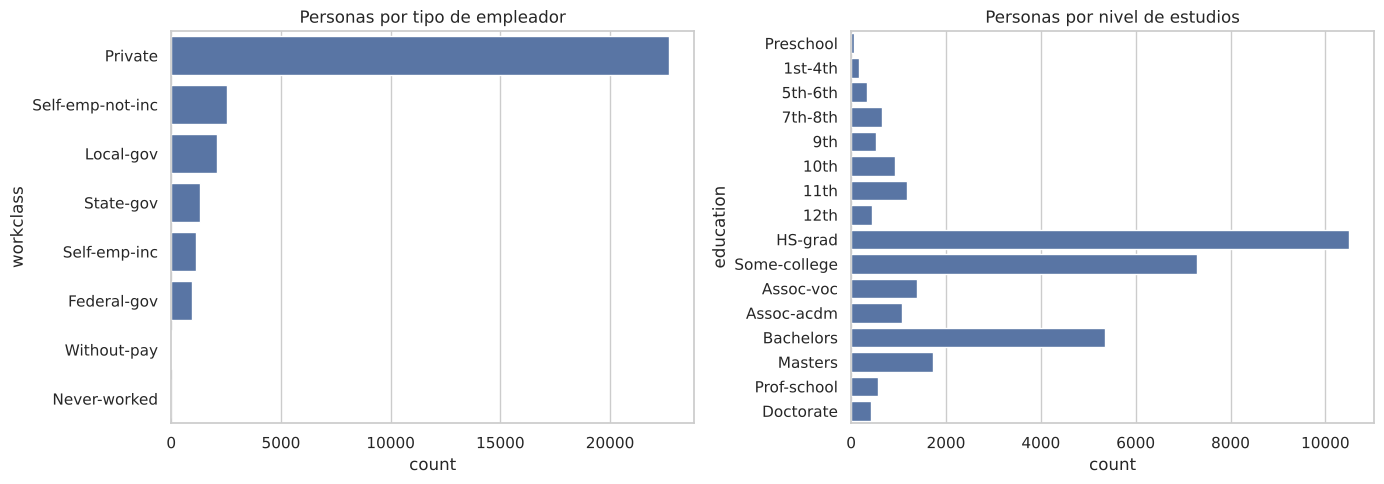

In [28]:
orden_edu = adult.sort_values("education-num")["education"].unique()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(y="workclass", data=adult, order=adult["workclass"].value_counts().index, ax=ax[0])
ax[0].set_title("Personas por tipo de empleador")
sns.countplot(y="education", data=adult, order=orden_edu, ax=ax[1])
ax[1].set_title("Personas por nivel de estudios")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/adult_categoricas.png")
plt.show()

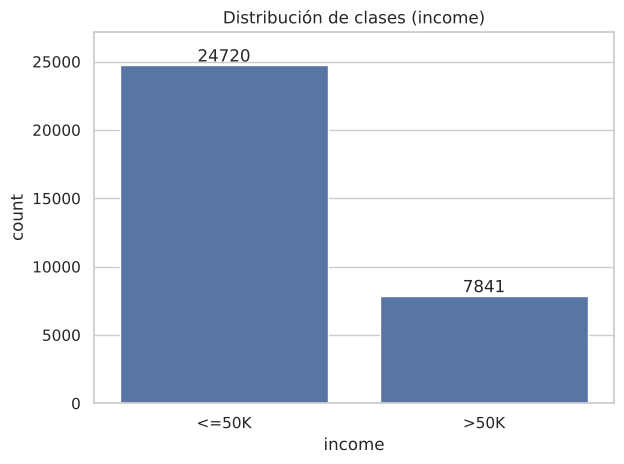

In [29]:
ax = sns.countplot(x="income", data=adult)
ax.bar_label(ax.containers[0])
ax.margins(y=0.1)
plt.title("Distribución de clases (income)")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/adult_clases.png")
plt.show()

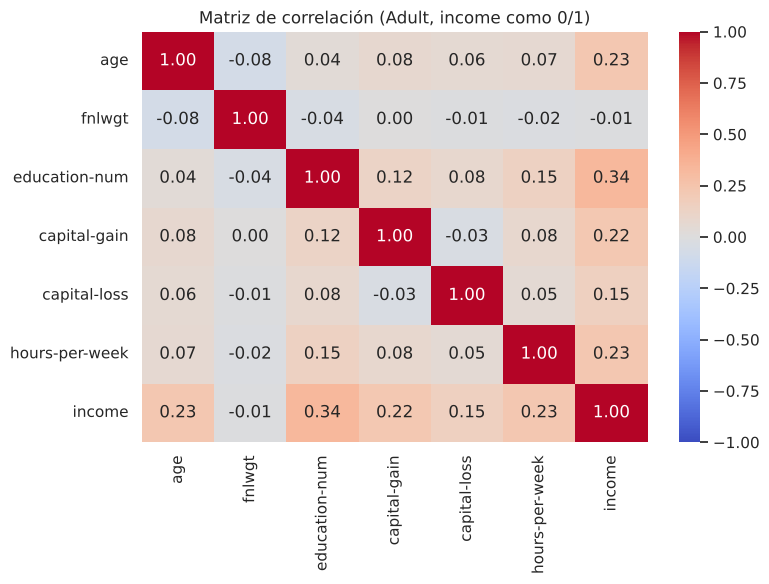

In [30]:
adult_num = adult.select_dtypes("number").copy()
adult_num["income"] = (adult["income"] == ">50K").astype(int)

plt.figure(figsize=(8, 6))
sns.heatmap(adult_num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación (Adult, income como 0/1)")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/adult_correlacion.png")
plt.show()

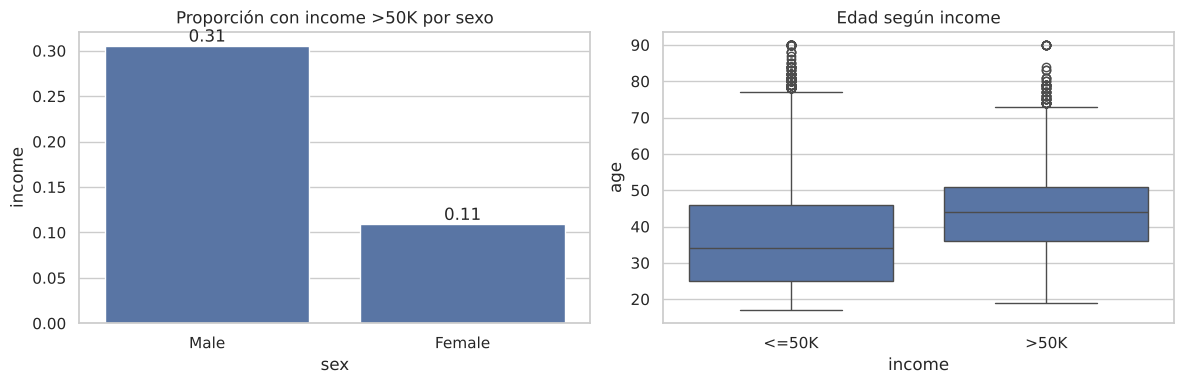

income
<=50K    34.0
>50K     44.0
Name: age, dtype: float64


In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=adult["sex"], y=adult_num["income"], errorbar=None, ax=ax[0])
ax[0].set_title("Proporción con income >50K por sexo")
ax[0].bar_label(ax[0].containers[0], fmt="%.2f")
sns.boxplot(x="income", y="age", data=adult, ax=ax[1])
ax[1].set_title("Edad según income")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/adult_atributo_objetivo.png")
plt.show()

print(adult.groupby("income")["age"].median())

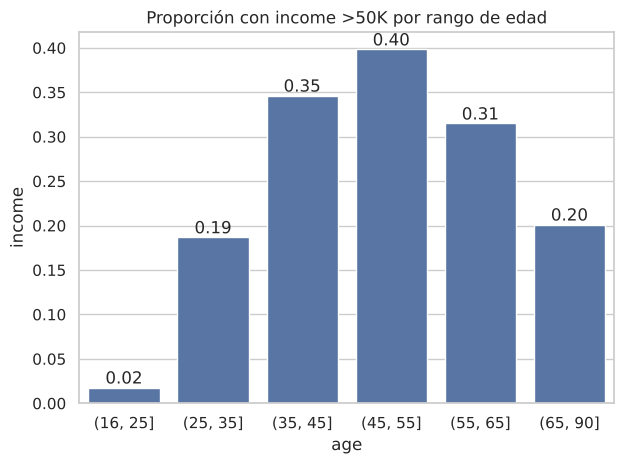

Correlación de age con income: 0.234


In [32]:
rangos_edad_ad = pd.cut(adult["age"], bins=[16, 25, 35, 45, 55, 65, 90])
ax = sns.barplot(x=rangos_edad_ad, y=adult_num["income"], errorbar=None)
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Proporción con income >50K por rango de edad")
plt.xlabel("age")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/adult_no_lineal.png")
plt.show()

print("Correlación de age con income:", round(adult["age"].corr(adult_num["income"]), 3))

**Hallazgos del EDA (Adult Income):**

- **age:** sesgada a la derecha. La mayoría tiene entre 25 y 50 años. El boxplot marca 143 valores atípicos arriba de 78 años, que son edades posibles y no errores.
- **hours-per-week:** tiene un pico enorme en 40 horas, porque el 46.7% de las personas trabaja exactamente eso. Por eso la caja del boxplot es muy angosta (de 40 a 45) y la regla del IQR marca 9,008 registros como atípicos (27.7%), incluyendo a gente que simplemente trabaja medio tiempo. Esto se considera en el tratamiento de outliers (Paso 5).
- **Categóricas:** el sector privado domina (22,696 personas, cerca del 70%). En estudios, lo más común es preparatoria terminada (HS-grad), seguido de universidad sin terminar (Some-college) y licenciatura (Bachelors).
- **Clases:** 24,720 ganan `<=50K` y 7,841 ganan `>50K`. El desbalance es más marcado que en Titanic.
- **Correlación:** lo que más se relaciona con el ingreso es `education-num` (0.34), seguido de `age` y `hours-per-week` (0.23 cada una) y `capital-gain` (0.22). `fnlwgt` tiene una correlación prácticamente nula (-0.01), lo que confirma que se puede descartar. Las variables numéricas casi no se relacionan entre sí (máximo 0.15), así que no hay redundancia fuerte entre ellas.
- **Atributo vs objetivo:** el 31% de los hombres gana más de 50K contra el 11% de las mujeres. Las personas que ganan más de 50K son más grandes: su edad mediana es de 44 años contra 34 del otro grupo.
- **Relación no lineal:** la correlación entre `age` y el ingreso es de 0.23, pero la relación tiene forma de U invertida. Entre 17 y 25 años solo el 1.8% gana más de 50K, sube hasta 39.8% entre 46 y 55 años y baja a 20.1% en mayores de 65. Un modelo lineal como la regresión logística no capta bien esta forma. Se podría usar la edad por rangos o un modelo basado en árboles.

## Paso 4. Imputación de valores perdidos

Se comparan dos estrategias para una variable numérica y dos para una categórica:

- **Numérica:** `Age` de Titanic (177 nulos, 19.9%). Media contra mediana.
- **Categórica:** `occupation` de Adult (1,843 nulos, 5.7%). Moda contra una categoría nueva llamada "Desconocido".

### 4.1 Age: media vs mediana

In [33]:
edad_media = titanic["Age"].fillna(titanic["Age"].mean())
edad_mediana = titanic["Age"].fillna(titanic["Age"].median())

comparacion_edad = pd.DataFrame({
    "original": titanic["Age"],
    "con_media": edad_media,
    "con_mediana": edad_mediana,
}).agg(["count", "mean", "median", "std", "var"]).round(2)
comparacion_edad

,original,con_media,con_mediana
count,714.00,891.00,891.00
mean,29.70,29.70,29.36
median,28.00,29.70,28.00
std,14.53,13.00,13.02
var,211.02,169.05,169.51


In [34]:
var_orig = titanic["Age"].var()
print("Cambio en varianza con media:", round((edad_media.var() - var_orig) / var_orig * 100, 2), "%")
print("Cambio en varianza con mediana:", round((edad_mediana.var() - var_orig) / var_orig * 100, 2), "%")

for nombre, serie in {"original": titanic["Age"].dropna(), "media": edad_media, "mediana": edad_mediana}.items():
    print(f"Valor más repetido ({nombre}): {serie.mode()[0]:.2f}, en {serie.value_counts(normalize=True).max() * 100:.2f}% de las filas")

Cambio en varianza con media: -19.89 %
Cambio en varianza con mediana: -19.67 %
Valor más repetido (original): 24.00, en 4.20% de las filas
Valor más repetido (media): 29.70, en 19.87% de las filas
Valor más repetido (mediana): 28.00, en 22.67% de las filas


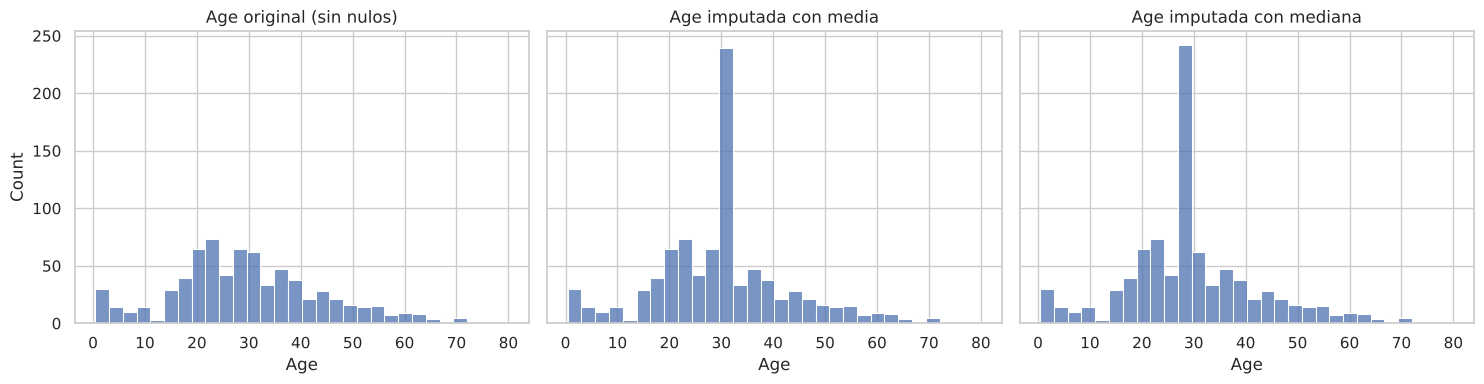

In [35]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
sns.histplot(titanic["Age"], bins=30, ax=ax[0])
ax[0].set_title("Age original (sin nulos)")
sns.histplot(edad_media, bins=30, ax=ax[1])
ax[1].set_title("Age imputada con media")
sns.histplot(edad_mediana, bins=30, ax=ax[2])
ax[2].set_title("Age imputada con mediana")
plt.tight_layout()
plt.savefig(f"{carpeta_graf}/imputacion_age.png")
plt.show()

In [36]:
print(titanic.groupby(titanic["Age"].isna())["Survived"].mean().round(3))

Age
False    0.406
True     0.294
Name: Survived, dtype: float64


In [37]:
def preparar_titanic(edad):
    datos = titanic.drop(columns=["PassengerId", "Name", "Ticket", "Cabin", "Survived"])
    datos["Age"] = edad
    datos["Embarked"] = datos["Embarked"].fillna(datos["Embarked"].mode()[0])
    return pd.get_dummies(datos, drop_first=True)

X_media = preparar_titanic(edad_media)
X_mediana = preparar_titanic(edad_mediana)
X_indicador = X_mediana.assign(Age_faltante=titanic["Age"].isna().astype(int))

pd.DataFrame({
    "media": evaluar(X_media, titanic["Survived"]),
    "mediana": evaluar(X_mediana, titanic["Survived"]),
    "mediana + Age_faltante": evaluar(X_indicador, titanic["Survived"]),
}).round(3)

,media,mediana,mediana + Age_faltante
accuracy,0.806,0.799,0.806
precision_minoritaria,0.758,0.743,0.768
recall_minoritaria,0.728,0.728,0.709
f1_minoritaria,0.743,0.735,0.737


**Resultado:** las dos estrategias bajan la varianza casi lo mismo, alrededor de 20% (de 211.02 a 169.05 con la media y a 169.51 con la mediana). Pasa porque los 177 nulos se llenan con un solo valor. Eso crea una concentración artificial: en los datos originales la edad más repetida (24) aparece en el 4.2% de las filas, pero después de imputar, 29.7 aparece en el 19.9% con la media y 28 en el 22.7% con la mediana. En la gráfica se ve como un pico y hace que los datos parezcan menos dispersos de lo que son.

**Desempeño del clasificador:** con la media, el F1 de la clase minoritaria es 0.743 y con la mediana 0.735. El recall es el mismo (0.728) y la diferencia en precisión equivale a unas 2 predicciones en un conjunto de prueba de 268 pasajeros, así que el modelo prácticamente no distingue entre las dos.

**Indicador de valor ausente:** que falte la edad sí dice algo. Sobrevivió el 29.4% de los pasajeros sin edad registrada, contra el 40.6% de los que sí la tienen. Por eso se crea la columna `Age_faltante` (1 si la edad venía vacía). En el modelo el F1 casi no cambia (de 0.735 a 0.737), porque 136 de las 177 edades faltantes son de tercera clase y `Pclass` ya le da esa información al modelo. Aun así se conserva, porque deja registrado qué edades son reales y cuáles se imputaron.

**Decisión:** se usa la **mediana** junto con `Age_faltante`. Como el desempeño es prácticamente igual, se elige por la distribución: la mediana conserva el valor central original (28), pierde un poco menos de varianza y no se ve afectada por valores extremos.

### 4.2 occupation: moda vs "Desconocido"

Para medir la variación en una categórica se usa el índice de Gini-Simpson, `1 - Σp²`, donde `p` es la proporción de cada categoría. Un valor más alto indica que los datos están más repartidos entre categorías.

In [38]:
def varianza_cat(serie):
    return 1 - (serie.value_counts(normalize=True) ** 2).sum()

moda_ocup = adult["occupation"].mode()[0]
ocup_moda = adult["occupation"].fillna(moda_ocup)
ocup_desc = adult["occupation"].fillna("Desconocido")

print("Moda:", moda_ocup)
print("Gini original:", round(varianza_cat(adult["occupation"]), 4))
print("Gini con moda:", round(varianza_cat(ocup_moda), 4))
print("Gini con Desconocido:", round(varianza_cat(ocup_desc), 4))

Moda: Prof-specialty
Gini original: 0.8945
Gini con moda: 0.8885
Gini con Desconocido: 0.9029


In [39]:
comparacion_ocup = pd.DataFrame({
    "original_%": adult["occupation"].value_counts(normalize=True),
    "con_moda_%": ocup_moda.value_counts(normalize=True),
    "con_desconocido_%": ocup_desc.value_counts(normalize=True),
}).mul(100).round(2)
comparacion_ocup

,original_%,con_moda_%,con_desconocido_%
occupation,,,
Adm-clerical,12.27,11.58,11.58
Armed-Forces,0.03,0.03,0.03
Craft-repair,13.34,12.59,12.59
Desconocido,NaN,NaN,5.66
Exec-managerial,13.24,12.49,12.49
Farming-fishing,3.24,3.05,3.05
Handlers-cleaners,4.46,4.21,4.21
Machine-op-inspct,6.52,6.15,6.15
Other-service,10.73,10.12,10.12


In [40]:
gana_mas = adult["income"] == ">50K"
print("% >50K en filas sin occupation:", round(gana_mas[adult["occupation"].isna()].mean() * 100, 2))
print("% >50K en Prof-specialty:", round(gana_mas[adult["occupation"] == moda_ocup].mean() * 100, 2))
print("% >50K en todo el dataset:", round(gana_mas.mean() * 100, 2))

% >50K en filas sin occupation: 10.36
% >50K en Prof-specialty: 44.9
% >50K en todo el dataset: 24.08


In [41]:
def preparar_adult(ocupacion):
    datos = adult.drop(columns=["fnlwgt", "income"])
    datos["occupation"] = ocupacion
    for col in ["workclass", "native-country"]:
        datos[col] = datos[col].fillna("Desconocido")
    return pd.get_dummies(datos, drop_first=True)

y_ingreso = (adult["income"] == ">50K").astype(int)

pd.DataFrame({
    "moda": evaluar(preparar_adult(ocup_moda), y_ingreso),
    "Desconocido": evaluar(preparar_adult(ocup_desc), y_ingreso),
}).round(3)

,moda,Desconocido
accuracy,0.853,0.853
precision_minoritaria,0.735,0.734
recall_minoritaria,0.611,0.612
f1_minoritaria,0.667,0.668


**Resultado:** con la moda, todos los nulos se van a `Prof-specialty`, que sube de 13.48% a 18.37%, y el índice de Gini baja de 0.8945 a 0.8885 (los datos quedan más concentrados). Con "Desconocido" las demás categorías bajan un poco de forma pareja, pero mantienen su orden y su peso relativo. El Gini sube a 0.9029 porque aparece una categoría más.

**Desempeño del clasificador:** las dos estrategias dan el mismo resultado (F1 de 0.667 con la moda y 0.668 con "Desconocido"). Tiene sentido, porque solo cambia el 5.7% de las filas y en 1,836 de esas 1,843 también falta `workclass`, que se llena con "Desconocido". El modelo ya tiene una señal de que esas filas son distintas.

**Decisión:** se usa **"Desconocido"**. Como el modelo no marca diferencia, se decide por lo que pasa con los datos. Los nulos no son aleatorios: de las personas sin ocupación, solo el 10.36% gana más de 50K, contra el 44.9% de `Prof-specialty`. Llenarlos con la moda metería a gente de bajo ingreso en la ocupación con más ingresos altos y ensuciaría la relación con la variable objetivo. Con "Desconocido" ese patrón se conserva. Además, esta categoría funciona como indicador de valor ausente: su columna dummy vale 1 justo en las filas donde faltaba el dato, así que no hace falta crear otra columna.

### 4.3 Datasets limpios

Con estas decisiones se arman los datasets que se usan en los siguientes pasos:

- **Titanic:** se quitan los identificadores (`PassengerId`, `Name`, `Ticket`) y `Cabin` por tener 77% de nulos. Se agrega `Age_faltante`, `Age` se llena con la mediana y `Embarked` con la moda (son solo 2 filas).
- **Adult:** se quita `fnlwgt`. `workclass`, `occupation` y `native-country` se llenan con "Desconocido".

La mediana y la moda se calculan con todo el dataset, antes de separar entrenamiento y prueba. Lo más correcto sería calcularlas solo con el entrenamiento, pero aquí el efecto es mínimo (la mediana de la edad sería 29 en vez de 28) y se prefirió mantener el código sencillo.

In [42]:
titanic_limpio = titanic.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])
titanic_limpio["Age_faltante"] = titanic_limpio["Age"].isna().astype(int)
titanic_limpio["Age"] = titanic_limpio["Age"].fillna(titanic_limpio["Age"].median())
titanic_limpio["Embarked"] = titanic_limpio["Embarked"].fillna(titanic_limpio["Embarked"].mode()[0])

adult_limpio = adult.drop(columns=["fnlwgt"])
for col in ["workclass", "occupation", "native-country"]:
    adult_limpio[col] = adult_limpio[col].fillna("Desconocido")

print("Nulos en titanic_limpio:", titanic_limpio.isna().sum().sum(), "| forma:", titanic_limpio.shape)
print("Nulos en adult_limpio:", adult_limpio.isna().sum().sum(), "| forma:", adult_limpio.shape)

Nulos en titanic_limpio: 0 | forma: (891, 9)
Nulos en adult_limpio: 0 | forma: (32561, 14)


## Paso 5. Outliers (Winsorización)

Los valores extremos se recortan a un límite en lugar de eliminar filas. Se comparan dos criterios para fijar los límites:

- **IQR:** límite inferior = Q1 - 1.5·IQR y límite superior = Q3 + 1.5·IQR, con IQR = Q3 - Q1. Son los mismos bigotes del boxplot.
- **Percentiles:** límites en el percentil 1 y el percentil 99.

Se aplica a `Fare` (Titanic) y a `hours-per-week` (Adult).

Además de comparar las distribuciones, se entrena la misma regresión logística con cada versión de la variable para ver si cambia el desempeño.

In [43]:
def winsor_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    rango = q3 - q1
    return serie.clip(q1 - 1.5 * rango, q3 + 1.5 * rango)

def winsor_pct(serie, bajo=0.01, alto=0.99):
    return serie.clip(serie.quantile(bajo), serie.quantile(alto))

def resumen(original, con_iqr, con_pct):
    tabla = pd.DataFrame({"original": original, "iqr": con_iqr, "percentiles": con_pct})
    tabla = tabla.agg(["min", "max", "mean", "median", "std"]).round(2)
    tabla.loc["valores_recortados"] = [0, (original != con_iqr).sum(), (original != con_pct).sum()]
    return tabla

def graficar_winsor(original, con_iqr, con_pct, nombre):
    versiones = {"original": original, "IQR": con_iqr, "percentiles 1-99": con_pct}
    fig, ax = plt.subplots(2, 3, figsize=(15, 6))
    for i, (titulo, datos) in enumerate(versiones.items()):
        sns.histplot(datos, bins=40, ax=ax[0, i])
        ax[0, i].set_title(f"{nombre} {titulo}")
        sns.boxplot(x=datos, ax=ax[1, i])
    plt.tight_layout()
    plt.savefig(f"{carpeta_graf}/winsor_{nombre}.png")
    plt.show()

def desempeno_winsor(X_base, y, columna, versiones):
    resultados = {}
    for nombre, valores in versiones.items():
        X = X_base.copy()
        X[columna] = valores
        resultados[nombre] = evaluar(pd.get_dummies(X, drop_first=True), y)
    return pd.DataFrame(resultados).round(3)

### 5.1 Fare (Titanic)

In [44]:
fare_iqr = winsor_iqr(titanic_limpio["Fare"])
fare_pct = winsor_pct(titanic_limpio["Fare"])
print("Recortados por IQR que son de primera clase:", (titanic_limpio.loc[fare_iqr != titanic_limpio["Fare"], "Pclass"] == 1).sum())

resumen(titanic_limpio["Fare"], fare_iqr, fare_pct)

Recortados por IQR que son de primera clase: 104


,original,iqr,percentiles
min,0.00,0.00,0.00
max,512.33,65.63,249.01
mean,32.20,24.05,31.22
median,14.45,14.45,14.45
std,49.69,20.48,42.52
valores_recortados,0.00,116.00,9.00


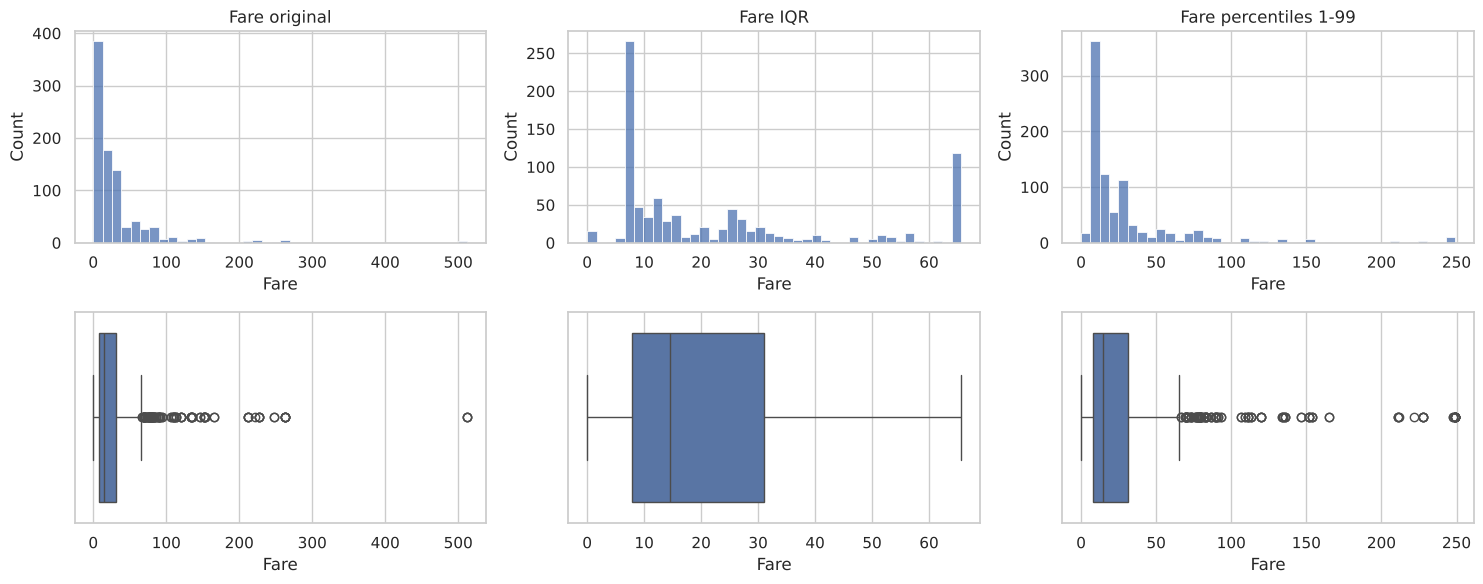

In [45]:
graficar_winsor(titanic_limpio["Fare"], fare_iqr, fare_pct, "Fare")

In [46]:
desempeno_winsor(titanic_limpio.drop(columns="Survived"), titanic_limpio["Survived"], "Fare",
                 {"original": titanic_limpio["Fare"], "IQR": fare_iqr, "percentiles": fare_pct})

,original,IQR,percentiles
accuracy,0.806,0.791,0.806
precision_minoritaria,0.768,0.737,0.768
recall_minoritaria,0.709,0.709,0.709
f1_minoritaria,0.737,0.723,0.737


### 5.2 hours-per-week (Adult)

In [47]:
horas_iqr = winsor_iqr(adult_limpio["hours-per-week"])
horas_pct = winsor_pct(adult_limpio["hours-per-week"])

resumen(adult_limpio["hours-per-week"], horas_iqr, horas_pct)

,original,iqr,percentiles
min,1.00,32.50,8.00
max,99.00,52.50,80.00
mean,40.44,41.20,40.39
median,40.00,40.00,40.00
std,12.35,6.19,11.94
valores_recortados,0.00,9008.00,503.00


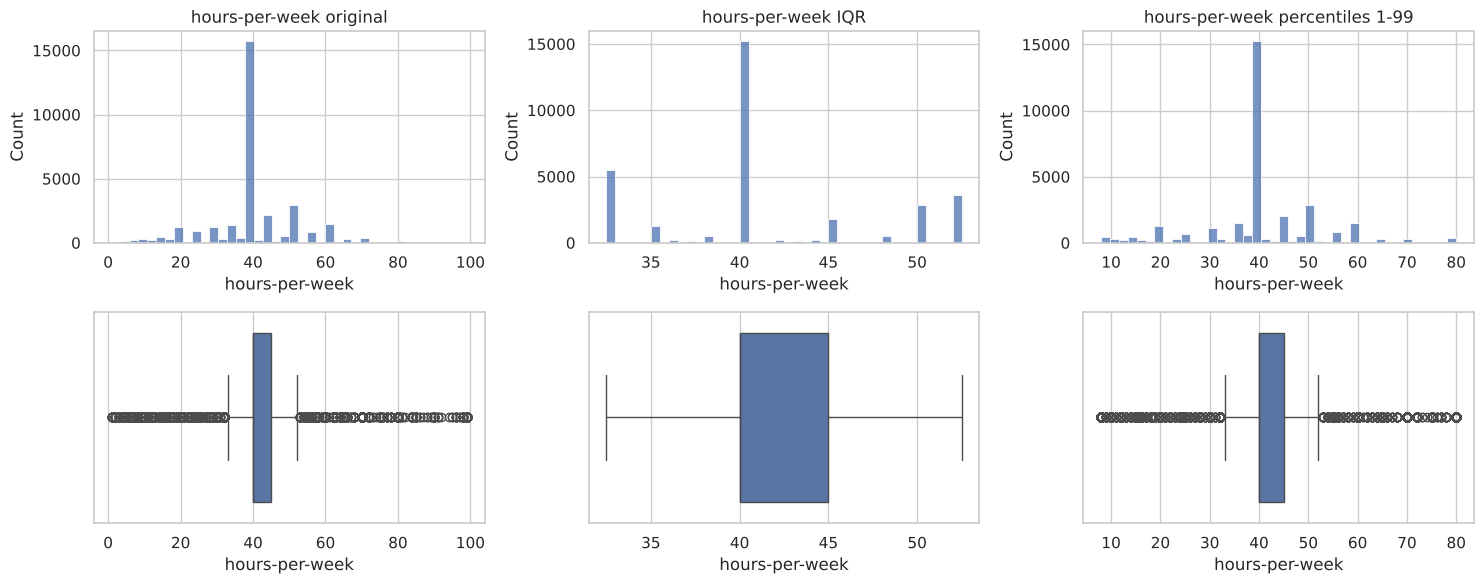

In [48]:
graficar_winsor(adult_limpio["hours-per-week"], horas_iqr, horas_pct, "hours-per-week")

In [49]:
desempeno_winsor(adult_limpio.drop(columns="income"), (adult_limpio["income"] == ">50K").astype(int), "hours-per-week",
                 {"original": adult_limpio["hours-per-week"], "IQR": horas_iqr, "percentiles": horas_pct})

,original,IQR,percentiles
accuracy,0.853,0.855,0.854
precision_minoritaria,0.734,0.741,0.738
recall_minoritaria,0.612,0.611,0.613
f1_minoritaria,0.668,0.670,0.670


**Resultados:**

| | Fare original | Fare IQR | Fare percentiles | Horas original | Horas IQR | Horas percentiles |
|---|---|---|---|---|---|---|
| Límites | 0 a 512.33 | 0 a 65.63 | 0 a 249.01 | 1 a 99 | 32.5 a 52.5 | 8 a 80 |
| Desv. estándar | 49.69 | 20.48 | 42.52 | 12.35 | 6.19 | 11.94 |
| Media | 32.20 | 24.05 | 31.22 | 40.44 | 41.20 | 40.39 |
| Valores recortados | - | 116 | 9 | - | 9,008 | 503 |
| F1 del modelo | 0.737 | 0.723 | 0.737 | 0.668 | 0.670 | 0.670 |

- **Fare con IQR:** recorta 116 boletos a 65.63, así que la desviación baja a menos de la mitad. Pero en el histograma se forma un pico de 116 pasajeros con el mismo precio, 104 de ellos de primera clase, casi la mitad de esa clase. Se pierde la diferencia entre un boleto de 70 y uno de 500.
- **Fare con percentiles:** solo toca 9 valores (el boleto de 512 y los más caros pasan a 249.01). La forma de la distribución casi no cambia y la media apenas baja de 32.20 a 31.22.
- **hours-per-week con IQR:** como el 46.7% trabaja exactamente 40 horas, la caja es muy angosta y los límites quedan en 32.5 y 52.5. Eso recorta 9,008 registros (27.7%): todas las personas que trabajan medio tiempo terminan con 32.5 horas, un valor que ni siquiera existía. La desviación se reduce a la mitad.
- **hours-per-week con percentiles:** solo recorta 503 valores (los que trabajan menos de 8 o más de 80 horas) y la desviación casi no cambia (de 12.35 a 11.94).
- **Desempeño del modelo:** el efecto es pequeño. En Titanic, el IQR baja el F1 de 0.737 a 0.723, porque al dejar a 116 pasajeros con el mismo precio el modelo pierde parte de la diferencia entre las clases. Con percentiles el desempeño queda igual que con los datos originales. En Adult las tres versiones quedan entre 0.668 y 0.670. En estos datos los valores extremos no estaban afectando mucho al modelo, así que la winsorización sirve más para tener distribuciones razonables que para subir las métricas.

**Decisión:** se usa la **winsorización por percentiles 1-99** en las dos variables. Controla los valores más extremos sin inventar picos artificiales ni borrar información real, y no empeora el modelo. El IQR funciona bien en variables con forma parecida a una campana, pero aquí aplasta demasiado los datos, sobre todo en `hours-per-week`.

In [50]:
titanic_limpio["Fare"] = fare_pct
adult_limpio["hours-per-week"] = horas_pct

print(titanic_limpio["Fare"].describe().round(2))
print(adult_limpio["hours-per-week"].describe().round(2))

count    891.00
mean      31.22
std       42.52
min        0.00
25%        7.91
50%       14.45
75%       31.00
max      249.01
Name: Fare, dtype: float64
count    32561.00
mean        40.39
std         11.94
min          8.00
25%         40.00
50%         40.00
75%         45.00
max         80.00
Name: hours-per-week, dtype: float64


## Paso 6. Tratamiento de desbalance

Para cada dataset se calcula la cantidad y el porcentaje de observaciones por clase, y la razón de desbalance IR = N_mayoritaria / N_minoritaria. Si IR > 1.5, el dataset se considera desbalanceado.

In [51]:
def razon_desbalance(serie):
    conteo = serie.value_counts()
    return conteo.max() / conteo.min()

for nombre, clase in {"Titanic": titanic_limpio["Survived"], "Adult": adult_limpio["income"]}.items():
    tabla_clases = pd.DataFrame({
        "cantidad": clase.value_counts(),
        "porcentaje": (clase.value_counts(normalize=True) * 100).round(2),
    })
    print(nombre)
    print(tabla_clases)
    print("IR:", round(razon_desbalance(clase), 2), "\n")

Titanic
          cantidad  porcentaje
Survived                      
0              549       61.62
1              342       38.38
IR: 1.61 

Adult
        cantidad  porcentaje
income                      
<=50K      24720       75.92
>50K        7841       24.08
IR: 3.15 



Los dos pasan de 1.5, así que los dos están desbalanceados, Adult bastante más que Titanic. Se prueban tres técnicas de remuestreo y se comparan contra la línea base sin balanceo:

| Estrategia | Qué hace | Riesgo principal |
|---|---|---|
| Sin balanceo | Entrena con las clases tal como vienen | El modelo tiende a ignorar la clase minoritaria |
| Sobremuestreo aleatorio | Copia filas de la clase minoritaria al azar hasta igualar a la mayoritaria | Sobreajuste, porque hay filas repetidas |
| Submuestreo aleatorio | Quita filas de la clase mayoritaria al azar hasta igualar a la minoritaria | Se pierde información |
| SMOTE | Crea filas nuevas de la clase minoritaria entre un caso y sus vecinos más cercanos | Casos artificiales poco realistas |

Para las tres se usa la librería `imbalanced-learn`. La técnica de balanceo va dentro de un pipeline junto con el escalado y la regresión logística. Así el balanceo solo se aplica al entrenamiento (70%) y el conjunto de prueba (30%) se queda con su distribución real. Si se balanceara antes de separar, filas copiadas o sintéticas podrían caer en prueba y el resultado saldría inflado.

El escalado va antes de SMOTE porque SMOTE busca vecinos por distancia. Sin escalar, una columna como `capital-gain` (de 0 a 99,999) pesaría mucho más que las demás.

In [52]:
estrategias = {
    "sin balanceo": None,
    "sobremuestreo": RandomOverSampler(random_state=42),
    "submuestreo": RandomUnderSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42),
}

def graficar_clases(X, y, nombre):
    X_train, _, y_train, _ = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    fig, ax = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
    for i, (tecnica, metodo) in enumerate(estrategias.items()):
        y_nuevo = y_train if metodo is None else metodo.fit_resample(X_train, y_train)[1]
        sns.countplot(x=y_nuevo, ax=ax[i])
        ax[i].set_title(f"{nombre}: {tecnica}")
        ax[i].bar_label(ax[i].containers[0])
    ax[0].set_ylim(0, y_train.value_counts().max() * 1.12)
    plt.tight_layout()
    plt.savefig(f"{carpeta_graf}/balanceo_{nombre}.png")
    plt.show()

### 6.1 Titanic

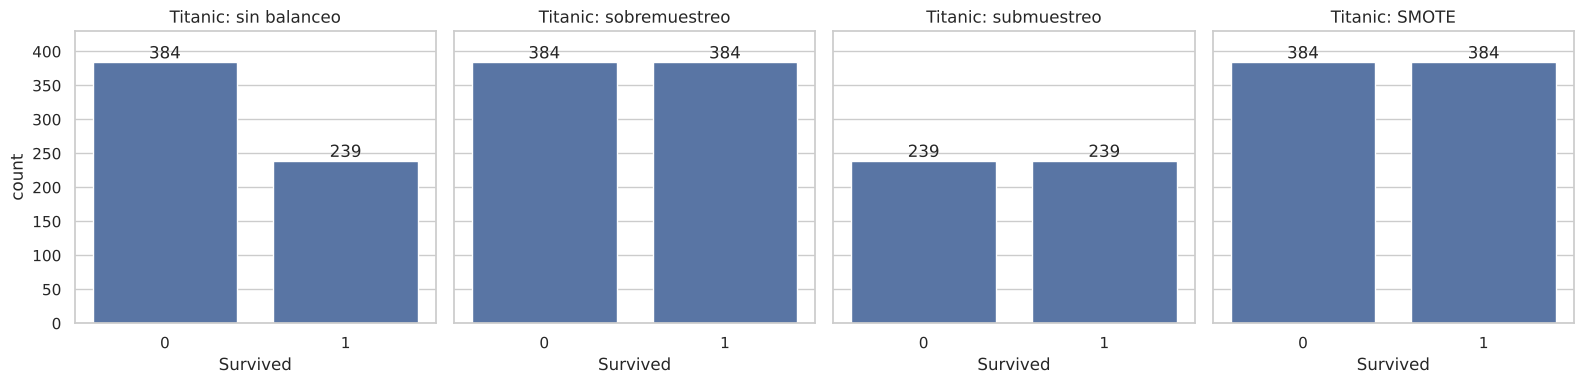

In [53]:
X_tit = pd.get_dummies(titanic_limpio.drop(columns="Survived"), drop_first=True)
y_tit = titanic_limpio["Survived"]

graficar_clases(X_tit, y_tit, "Titanic")

In [54]:
resultados_tit = pd.DataFrame({nombre: evaluar(X_tit, y_tit, tecnica) for nombre, tecnica in estrategias.items()})
resultados_tit.round(3)

,sin balanceo,sobremuestreo,submuestreo,SMOTE
accuracy,0.806,0.795,0.817,0.810
precision_minoritaria,0.768,0.703,0.750,0.728
recall_minoritaria,0.709,0.806,0.786,0.806
f1_minoritaria,0.737,0.751,0.768,0.765


### 6.2 Adult Income

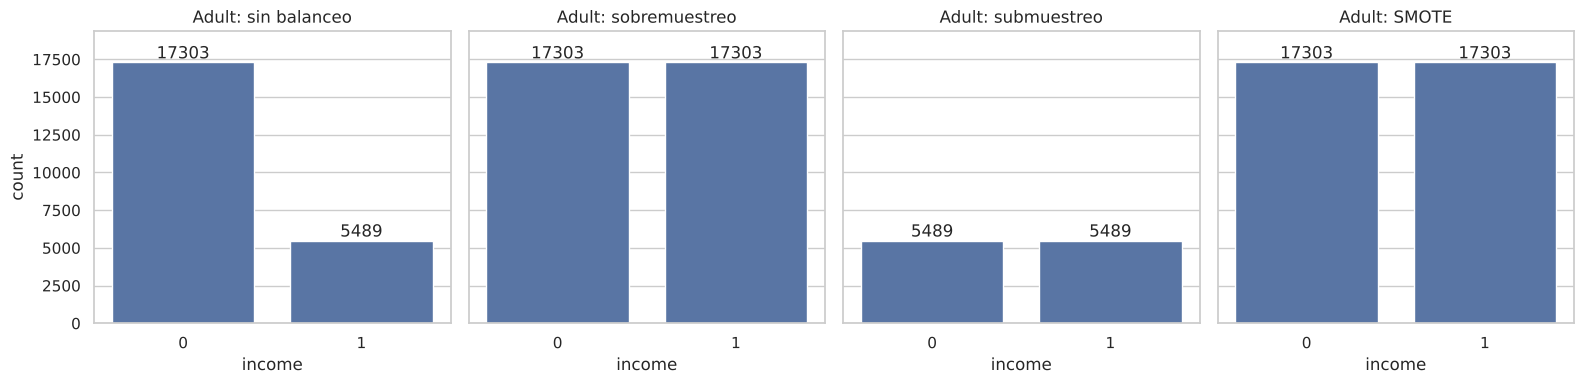

In [55]:
X_adult = pd.get_dummies(adult_limpio.drop(columns="income"), drop_first=True)
y_adult = (adult_limpio["income"] == ">50K").astype(int)

graficar_clases(X_adult, y_adult, "Adult")

In [56]:
resultados_adult = pd.DataFrame({nombre: evaluar(X_adult, y_adult, tecnica) for nombre, tecnica in estrategias.items()})
resultados_adult.round(3)

,sin balanceo,sobremuestreo,submuestreo,SMOTE
accuracy,0.854,0.807,0.810,0.810
precision_minoritaria,0.738,0.566,0.570,0.570
recall_minoritaria,0.613,0.857,0.856,0.855
f1_minoritaria,0.670,0.682,0.684,0.684


**Resultados:**

| Estrategia | Filas de entrenamiento (Adult) | Recall Titanic | F1 Titanic | Recall Adult | Precision Adult | F1 Adult |
|---|---|---|---|---|---|---|
| Sin balanceo | 22,792 | 0.709 | 0.737 | 0.613 | 0.738 | 0.670 |
| Sobremuestreo | 34,606 | 0.806 | 0.751 | 0.857 | 0.566 | 0.682 |
| Submuestreo | 10,978 | 0.786 | 0.768 | 0.856 | 0.570 | 0.684 |
| SMOTE | 34,606 | 0.806 | 0.765 | 0.855 | 0.570 | 0.684 |

- **Lo que tienen en común:** las tres técnicas suben mucho el recall de la clase minoritaria. En Adult, el modelo sin balanceo solo detectaba al 61.3% de las personas que ganan más de 50K, y con cualquiera de las tres detecta cerca del 85.6%.
- **El costo también es el mismo:** la precisión baja (en Adult, de 0.738 a 0.57) y la accuracy también (de 0.854 a 0.81), porque ahora el modelo marca como `>50K` a más personas que en realidad no lo son. Aun así, el F1 sube en todos los casos.
- **Las diferencias entre técnicas son muy chicas:** en Adult el F1 queda entre 0.682 y 0.684. En Titanic el conjunto de prueba tiene 103 sobrevivientes, así que la diferencia de recall entre el submuestreo (0.786) y las otras dos (0.806) son solo dos personas. Con tan pocos datos no se puede decir que una técnica sea mejor que otra.
- **Lo que sí cambia es qué le hace cada una a los datos:** el submuestreo llega al mismo resultado, pero tira 11,814 filas de la clase mayoritaria (68% de esa clase). SMOTE crea filas que no existen y, como trabaja sobre variables dummy, genera valores intermedios en columnas que solo deberían valer 0 o 1 (por ejemplo, un pasajero "40% hombre"). El sobremuestreo solo repite filas reales.
- **La accuracy engaña:** un modelo que dijera `<=50K` para todos tendría 75.9% de accuracy sin detectar a nadie de la clase minoritaria. Por eso se comparan precision, recall y F1 de la clase minoritaria.

**Decisión:** se recomienda el **sobremuestreo aleatorio**. Da prácticamente el mismo resultado que las otras dos, no pierde registros como el submuestreo y no inventa casos como SMOTE. Además es la más fácil de explicar. Si el dataset fuera mucho más grande, el submuestreo sería una buena opción, porque entrena con menos datos y llega a lo mismo.

## Conclusiones

1. **Los valores faltantes no son aleatorios.** En Titanic falta más la edad en tercera clase y los pasajeros sin edad sobreviven menos (29.4% contra 40.6%). En Adult, las personas sin ocupación registrada ganan más de 50K mucho menos que el promedio (10.36% contra 24.08%). Por eso se agregó `Age_faltante` y se usó la categoría "Desconocido".
2. **Imputar con un solo valor deforma la variable.** Con 20% de nulos, la varianza de `Age` bajó cerca de 20% y el valor imputado quedó en el 22.7% de las filas. El clasificador casi no distingue entre media y mediana, ni entre moda y "Desconocido", así que la decisión se tomó por lo que pasa con la distribución y con la relación con el objetivo.
3. **La regla del IQR no sirve para todas las variables.** En `hours-per-week`, como casi la mitad de las personas trabaja 40 horas, el IQR marcó como atípicos al 27.7% de los registros. En `Fare` dejó a 116 pasajeros con el mismo precio y bajó el F1 del modelo de 0.737 a 0.723. Los percentiles 1-99 solo recortaron los casos más extremos y no empeoraron el modelo.
4. **La accuracy sola engaña.** En Adult, el modelo sin balanceo tiene 85.4% de accuracy, pero solo detecta al 61.3% de las personas que ganan más de 50K. Con cualquiera de las tres técnicas de balanceo el recall sube a cerca de 85.6%, a cambio de más falsos positivos. Las tres técnicas dieron resultados casi iguales.
5. **La correlación no muestra todo.** La edad casi no se correlaciona con la supervivencia (-0.08), pero los niños sobreviven mucho más que los adultos mayores. En Adult el ingreso alto sube con la edad hasta los 55 años y después baja.
6. **Los datos tienen sesgos.** En Adult, los hombres ganan más de 50K casi tres veces más que las mujeres (30.6% contra 10.9%), y hay diferencias parecidas por raza. Un modelo entrenado con estos datos puede repetir esa desigualdad.

## Recomendación

- **Preparación de Titanic:** quitar `PassengerId`, `Name`, `Ticket` y `Cabin`; imputar `Age` con la mediana y agregar `Age_faltante`; imputar `Embarked` con la moda; winsorizar `Fare` con percentiles 1-99.
- **Preparación de Adult:** quitar `fnlwgt`; llenar `workclass`, `occupation` y `native-country` con "Desconocido"; winsorizar `hours-per-week` con percentiles 1-99.
- **Balanceo:** usar sobremuestreo aleatorio y aplicarlo solo al conjunto de entrenamiento.
- **Evaluación:** medir con precision, recall y F1 de la clase minoritaria, no solo con accuracy.
- **Siguientes pasos:** probar la edad por rangos o un modelo basado en árboles para captar las relaciones no lineales, y revisar el desempeño por sexo y raza antes de usar un modelo de Adult para tomar decisiones sobre personas.